# Hafta 8 · Görüntü İşlemenin Temelleri

**Yapay Zekâya Giriş — Laboratuvar Defteri**  
Dr. Seda Bayat Toksöz · Iğdır Üniversitesi · 2026–2027 Güz

Bu defterde OpenCV ve scikit-image ile gri ton dönüşümü, taşma ve normalizasyon, histogram eşitleme, Otsu eşikleme, filtreleme, kenar bulma, madeni para sayma ve bir çekirdeği veriden öğrenme uygulanır. Örnek görüntüler scikit-image kütüphanesiyle birlikte gelir; internetten dosya indirmeye gerek yoktur. Kendi görüntünüzü denemek için dosyayı Colab'a yükleyip `img = cv2.imread("ornek.jpg")` ile okuyabilirsiniz.

Hücreleri yukarıdan aşağıya sırayla çalıştırın (**Shift + Enter**). Parametreleri değiştirip sonucun nasıl değiştiğini gözlemleyin.

In [1]:
# Grafik ayarları (ders notlarıyla aynı renk paleti)
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#56B4E9", "#CC79A7"]),
})

## 1. Görüntü bir sayı matrisidir (Çözümlü Örnek 8.1)

In [2]:
import cv2
import numpy as np
from skimage import data

rgb = data.astronaut()                       # örnek renkli görüntü
img = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)   # OpenCV BGR sırası
gri = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)  # gri tona çevir
print(img.shape, gri.shape, gri.dtype)
print(gri[:4, :4])                           # sol üst 4x4 bölge

piksel = np.uint8([[[50, 100, 200]]])  # BGR: R=200, G=100, B=50
print("gri ton:", cv2.cvtColor(piksel, cv2.COLOR_BGR2GRAY)[0, 0])
print("bayt   :", 1920 * 1080 * 3)     # sıkıştırılmamış Full HD

(512, 512, 3) (512, 512) uint8
[[150 107  65  57]
 [173 142 115 108]
 [196 179 166 158]
 [215 208 199 193]]
gri ton: 124
bayt   : 6220800


### uint8 taşması ve normalizasyon
Piksel değerleri 0–255 aralığındaki `uint8` sayılardır. Toplama yaparken dikkat!

In [3]:
a = np.array([[250, 100]], np.uint8)
b = np.array([[10, 10]], np.uint8)
print("NumPy :", a + b)           # taşma: 260 → 4
print("OpenCV:", cv2.add(a, b))   # doyma: 255'te durur
x = gri.astype(np.float32) / 255  # [0, 1] aralığına normalizasyon
print("float :", x.dtype, x.min(), x.max())

NumPy : [[  4 110]]
OpenCV: [[255 110]]
float : float32 0.0 1.0


### Yardımcı fonksiyon
Görüntüleri ızgara hâlinde yan yana çizmek için kullanacağız.

In [4]:
import matplotlib.pyplot as plt

def goster(goruntuler, basliklar, sutun=4, cmap="gray"):
    """Görüntüleri ızgara hâlinde çizer."""
    satir = -(-len(goruntuler) // sutun)
    fig, eksen = plt.subplots(satir, sutun, figsize=(3 * sutun, 2.6 * satir))
    for ax, g, b in zip(np.ravel(eksen), goruntuler, basliklar):
        ax.imshow(np.asarray(g), cmap=cmap)
        ax.set_title(b)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### Deneyin: HSV ile kırmızı nesneleri bulmak
OpenCV'de H (ton) 0–179 aralığındadır; kırmızı bu çemberin iki ucundadır.

kırmızı piksel oranı: % 22.6


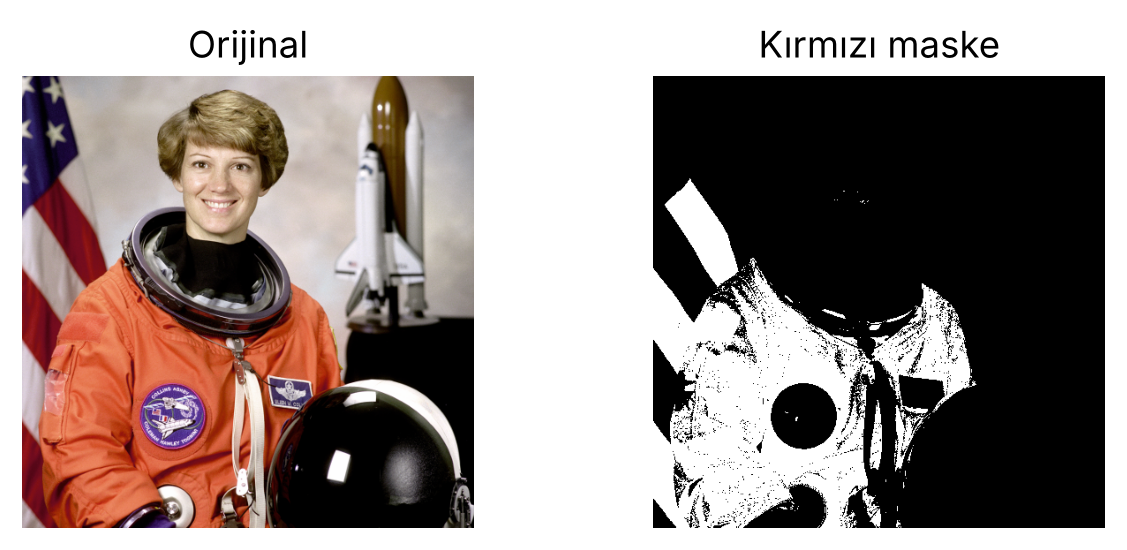

In [5]:
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
alt = cv2.inRange(hsv, (0, 120, 70), (8, 255, 255))     # kırmızının bir ucu
ust = cv2.inRange(hsv, (170, 120, 70), (179, 255, 255)) # öbür ucu
maske = alt | ust
print("kırmızı piksel oranı: %", round(100 * (maske > 0).mean(), 1))
goster([rgb, maske], ["Orijinal", "Kırmızı maske"], sutun=2)

## 2. Histogram eşitleme ve Otsu eşikleme

Otsu eşiği: 107.0


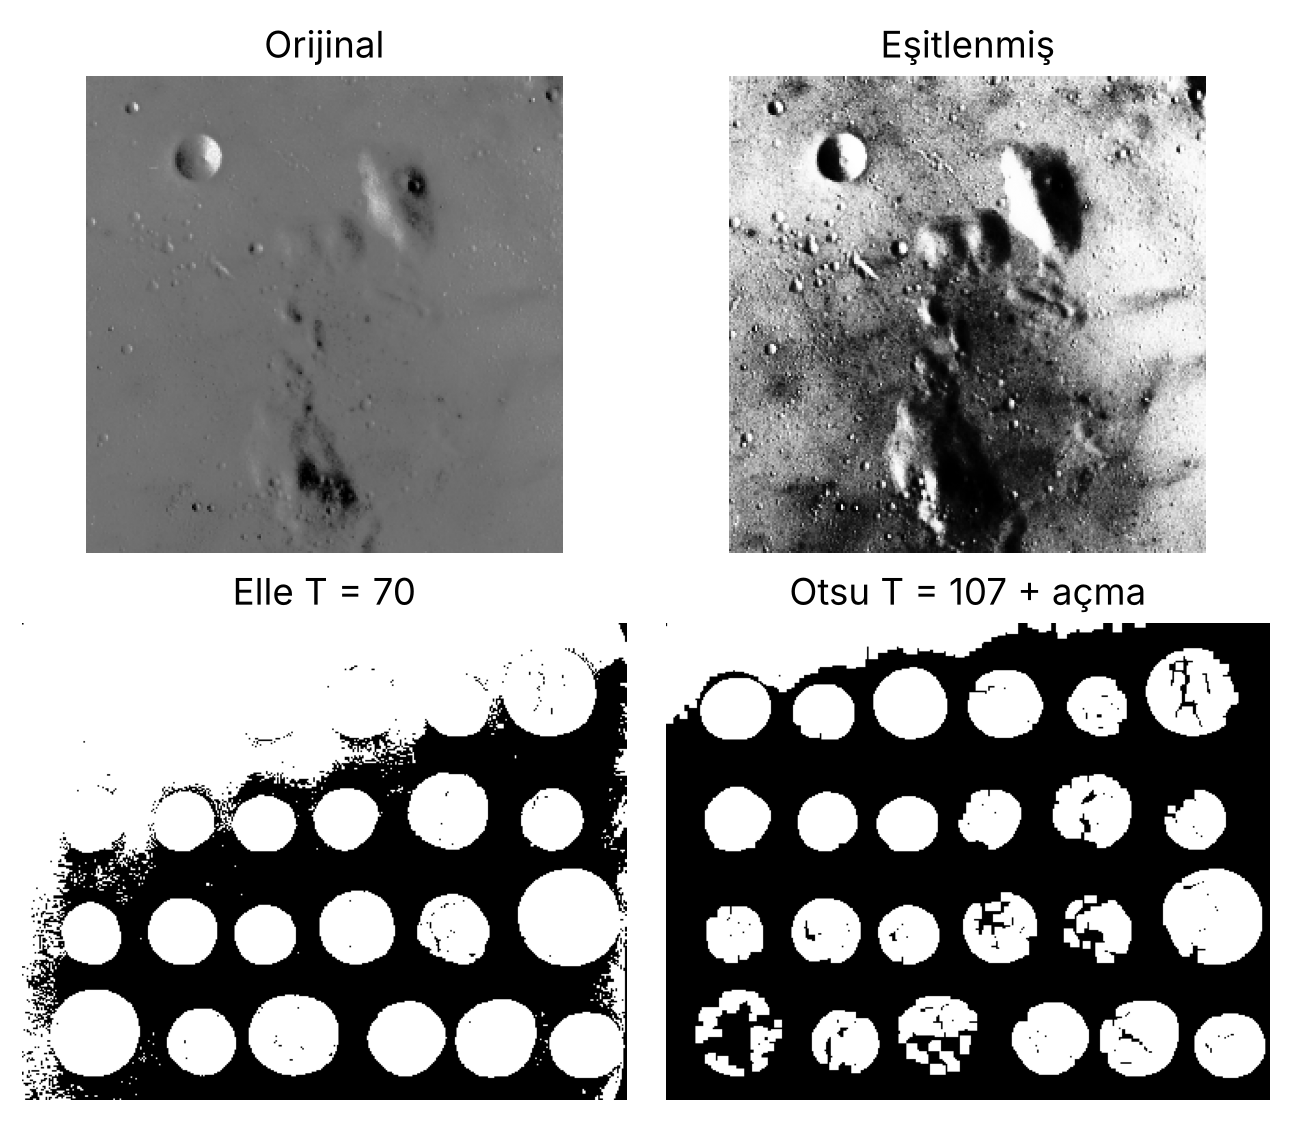

In [6]:
ay = data.moon()               # düşük kontrast
esit = cv2.equalizeHist(ay)    # histogram eşitleme

para = data.coins()
_, elle = cv2.threshold(para, 70, 255, cv2.THRESH_BINARY)
T, ikili = cv2.threshold(para, 0, 255,
                         cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Otsu eşiği:", T)
cekirdek = np.ones((5, 5), np.uint8)
temiz = cv2.morphologyEx(ikili, cv2.MORPH_OPEN, cekirdek)

goster([ay, esit, elle, temiz],
       ["Orijinal", "Eşitlenmiş", "Elle T = 70",
        f"Otsu T = {T:.0f} + açma"], sutun=2)

## 3. Elle yaptığımız hesapları kodla doğrulamak

In [7]:
# Şekil 8.5: 5x5 girdi ve 3x3 çekirdek (yalnızca dolgusuz bölge)
I = np.float32([[1, 1, 1, 0, 0], [0, 1, 1, 1, 0], [0, 0, 1, 1, 1],
                [0, 0, 1, 1, 0], [0, 1, 1, 0, 0]])
K = np.float32([[1, 0, 1], [0, 1, 0], [1, 0, 1]])
print(cv2.filter2D(I, -1, K)[1:-1, 1:-1])

# Çözümlü Örnek 8.5: Sobel Gx ile dikey kenar
S = np.tile(np.float32([10, 10, 10, 80, 80]), (5, 1))
sobel_x = np.float32([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
print(cv2.filter2D(S, -1, sobel_x)[1:-1, 1:-1])

# Çözümlü Örnek 8.4: gürültü noktasında ortalama ve medyan
k = np.array([[12, 15, 13], [14, 255, 16], [13, 12, 14]])
print("ortalama:", round(k.mean(), 1), "| medyan:", np.median(k))

[[4. 3. 4.]
 [2. 4. 3.]
 [2. 3. 4.]]
[[  0. 280. 280.]
 [  0. 280. 280.]
 [  0. 280. 280.]]
ortalama: 40.4 | medyan: 14.0


## 4. Filtreler ve kenar bulma
Tuz-biber gürültüsünü kendimiz ekleyip medyan filtresiyle temizliyoruz.

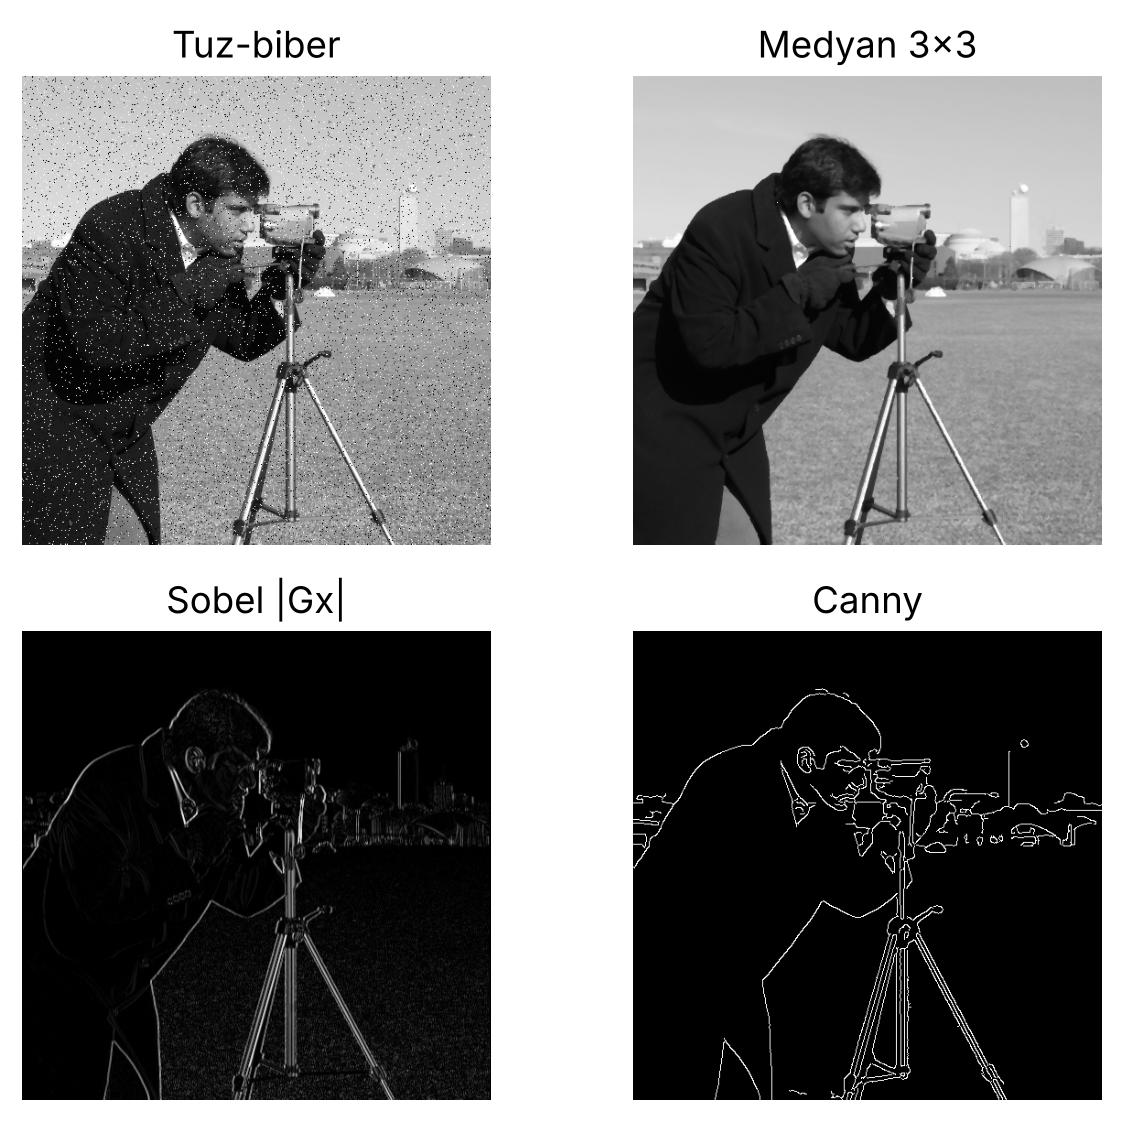

In [8]:
gri = data.camera()
bulanik = cv2.GaussianBlur(gri, (5, 5), 1.5)  # Gauss
rng = np.random.default_rng(0)
u = rng.random(gri.shape)
gurultu = gri.copy()                          # tuz-biber
gurultu[u < 0.025] = 0
gurultu[u > 0.975] = 255
medyan = cv2.medianBlur(gurultu, 3)           # medyan

sobel_x = np.float32([[-1, 0, 1],             # kendi
                      [-2, 0, 2],             # çekirdeğimiz
                      [-1, 0, 1]])
gx = cv2.filter2D(gri.astype(np.float32), -1, sobel_x)
kenar = cv2.Canny(bulanik, 50, 150)           # Canny

goster([gurultu, medyan, np.abs(gx), kenar],
       ["Tuz-biber", "Medyan 3×3", "Sobel |Gx|", "Canny"],
       sutun=2)

## 5. Uygulama: madeni paraları saymak
Yumuşatma → eşikleme → morfoloji → bağlantılı bileşen etiketleme: klasik bir endüstriyel sayım hattı. Gauss satırını silip sonucun nasıl bozulduğunu deneyin.

para sayısı: 24


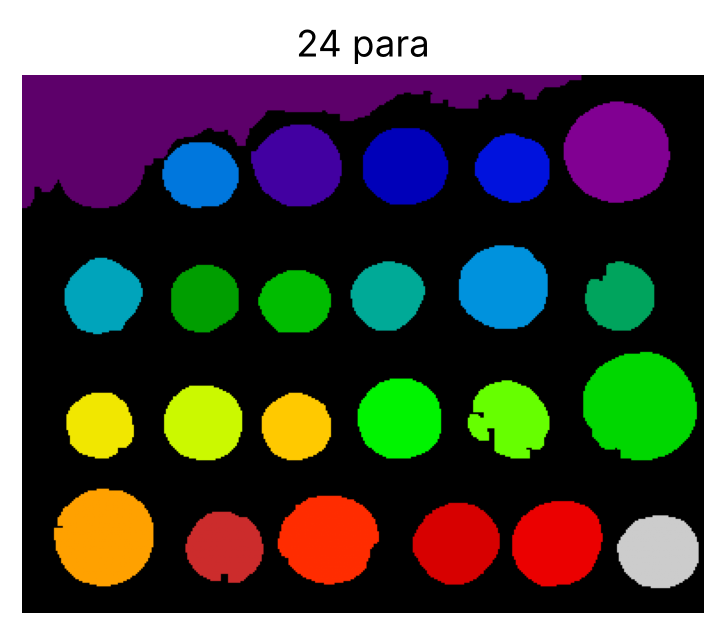

In [9]:
from scipy import ndimage
para = data.coins()
yumusak = cv2.GaussianBlur(para, (5, 5), 0)
_, ikili = cv2.threshold(yumusak, 0, 255,
                         cv2.THRESH_BINARY + cv2.THRESH_OTSU)
ac = cv2.morphologyEx(ikili, cv2.MORPH_OPEN,
                      np.ones((5, 5), np.uint8))
dolu = ndimage.binary_fill_holes(ac > 0)  # delikleri doldur
etiket, n = ndimage.label(dolu)           # her paraya numara
print("para sayısı:", n)

plt.figure(figsize=(4, 3.4))
plt.imshow(etiket, cmap="nipy_spectral")
plt.title(f"{n} para"); plt.axis("off"); plt.show()

## 6. CNN'e köprü: bir çekirdeği veriden öğrenmek
Sobel çekirdeğini kimseye söylemeden, yalnızca girdi ve 'doğru çıktı' örneklerinden öğrenebilir miyiz?

In [10]:
import torch
import torch.nn.functional as F

x = torch.tensor(data.camera()[::2, ::2] / 255.0,  # 256x256 girdi
                 dtype=torch.float32)[None, None]
sobel = torch.tensor([[-1., 0, 1],
                      [-2, 0, 2],
                      [-1, 0, 1]])[None, None]
hedef = F.conv2d(x, sobel)                  # "doğru cevap" görüntüsü

torch.manual_seed(0)
K = torch.randn(1, 1, 3, 3, requires_grad=True)   # rastgele başla
opt = torch.optim.Adam([K], lr=0.1)
for adim in range(2001):
    kayip = ((F.conv2d(x, K) - hedef) ** 2).mean()
    opt.zero_grad(); kayip.backward(); opt.step()
    if adim % 500 == 0:
        print(f"adım {adim:4d}  kayıp = {kayip.item():.6f}")
print(K.detach().squeeze().round(decimals=2))

adım    0  kayıp = 2.408927


adım  500  kayıp = 0.000499


adım 1000  kayıp = 0.000011


adım 1500  kayıp = 0.000000


adım 2000  kayıp = 0.000000
tensor([[-1.,  0.,  1.],
        [-2., -0.,  2.],
        [-1.,  0.,  1.]])


### Alıştırma (Değerlendirme Soruları 8 ve 11)
Önce kâğıt üzerinde çözün, sonra hücreyi çalıştırıp karşılaştırın.

In [ ]:
# Soru 8: 2x2 çekirdek, dolgusuz, adım 1
I = np.array([[3, 1, 2, 0], [0, 2, 1, 3], [1, 0, 4, 2], [2, 1, 0, 1]])
K = np.array([[1, 0], [0, -1]])
O = np.array([[np.sum(I[i:i+2, j:j+2] * K) for j in range(3)] for i in range(3)])
print(O)

# Soru 11: 3 bitlik görüntüde histogram eşitleme
n = np.array([6, 5, 3, 1, 1, 0, 0, 0])
print("dönüşüm:", np.round(7 * np.cumsum(n) / n.sum()).astype(int))